Task 6: Support Vector Machine vs. Linear Classifier Boundary (Iris Dataset)
● Exam Task:
1. Load the Iris dataset, drop the Id column, and select two continuous features
(e.g., Petal Length and Petal Width) for 2D visualization.
2. Standardize features and split the data into train and test sets.
3. Train a Linear SVM (SVC(kernel='linear')) and a Logistic Regression
model on the same two features
4. Identify and print the coordinates/indices of the Support Vectors
5. Plot the decision boundaries of both classifiers on the same plot or side-by-side
subplots to illustrate maximum margin separation vs. a standard linear boundary

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

# 1. Load the Iris dataset
iris = datasets.load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target

# Using 'petal length (cm)' and 'petal width (cm)' as the two continuous features
features = ['petal length (cm)', 'petal width (cm)']
X = df[features].values
y = df['target'].values

print("Dataset loaded successfully.")
print(f"Selected features: {features}")
print(f"Shape of X: {X.shape}")

Dataset loaded successfully.
Selected features: ['petal length (cm)', 'petal width (cm)']
Shape of X: (150, 2)


In [ ]:
# 2. Standardize features and split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

print("Features standardized and dataset split completed.")

Features standardized and dataset split completed.


In [ ]:
# 3. Train a Linear SVM (SVC with linear kernel) and a Logistic Regression model
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train_std, y_train)

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_std, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [ ]:
# 4. Identify and print the coordinates/indices of the Support Vectors
support_vector_indices = svm_model.support_
support_vectors_standardized = svm_model.support_vectors_

# Inverse transform to get original coordinates for display
support_vectors_original = scaler.inverse_transform(support_vectors_standardized)

print(f"Number of support vectors: {len(support_vector_indices)}")
print("\nIndices of Support Vectors in the training set:\n", support_vector_indices)
print("\nStandardized coordinates of Support Vectors (Petal Length, Petal Width):\n", support_vectors_standardized[:10], "..." if len(support_vectors_standardized) > 10 else "")
print("\nOriginal coordinates of Support Vectors (Petal Length, Petal Width):\n", support_vectors_original[:10], "..." if len(support_vectors_original) > 10 else "")

Number of support vectors: 22

Indices of Support Vectors in the training set:
 [ 79  84   0   1  13  19  28  59  60  63  69  93 101  21  37  42  53  74
  81  82  85  98]

Standardized coordinates of Support Vectors (Petal Length, Petal Width):
 [[-1.06151687 -1.04119311]
 [-1.17415888 -1.04119311]
 [-0.4419858  -0.13661044]
 [ 0.40282929  0.38029394]
 [ 0.40282929  0.38029394]
 [ 0.57179231  0.76797223]
 [ 0.62811332  0.38029394]
 [ 0.51547131  0.38029394]
 [ 0.57179231  0.25106784]
 [ 0.74075533  0.50952003]] ...

Original coordinates of Support Vectors (Petal Length, Petal Width):
 [[1.9 0.4]
 [1.7 0.4]
 [3.  1.1]
 [4.5 1.5]
 [4.5 1.5]
 [4.8 1.8]
 [4.9 1.5]
 [4.7 1.5]
 [4.8 1.4]
 [5.1 1.6]] ...


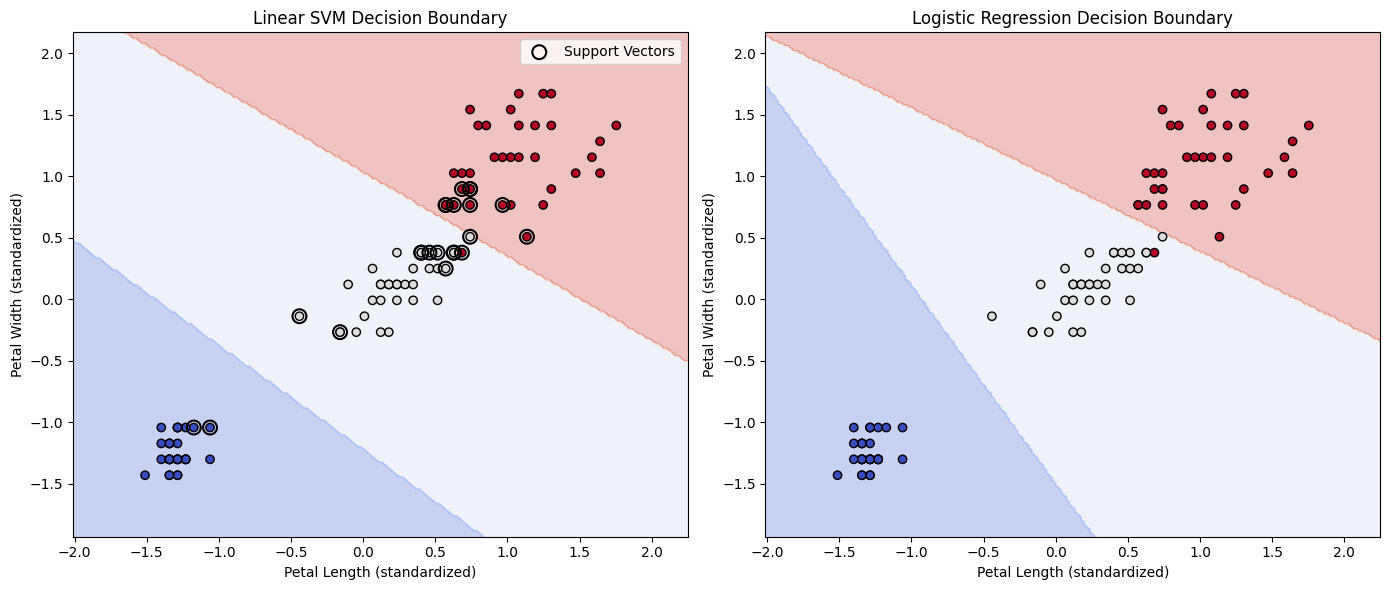

In [ ]:
# 5. Plot the decision boundaries side-by-side
def plot_decision_boundary(model, X, y, ax, title, svm=False):
    # Set up meshgrid
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

    # Predict
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot boundary and training points
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')

    # Highlight support vectors if SVM
    if svm:
        ax.scatter(svm_model.support_vectors_[:, 0], svm_model.support_vectors_[:, 1],
                   s=100, facecolors='none', edgecolors='black', linewidths=1.5, label='Support Vectors')
        ax.legend()

    ax.set_title(title)
    ax.set_xlabel('Petal Length (standardized)')
    ax.set_ylabel('Petal Width (standardized)')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Linear SVM
plot_decision_boundary(svm_model, X_train_std, y_train, axes[0], 'Linear SVM Decision Boundary', svm=True)

# Plot Logistic Regression
plot_decision_boundary(lr_model, X_train_std, y_train, axes[1], 'Logistic Regression Decision Boundary', svm=False)

plt.tight_layout()
plt.show()